In [1]:
load("visualize.sage")
load("curves.sage")

# Plane curves
We consider a general curve $\mathbb P^2$ of degree $d$.

Ideal (-x0^4 + x0^3*x1 + 12*x0^2*x1^2 + 3*x0*x1^3 - x1^4 + 6*x1^3*x2 - x0^2*x2^2 - 2*x0*x1*x2^2 - x1^2*x2^2 - x0*x2^3 + x1*x2^3) of Multivariate Polynomial Ring in x0, x1, x2 over Rational Field


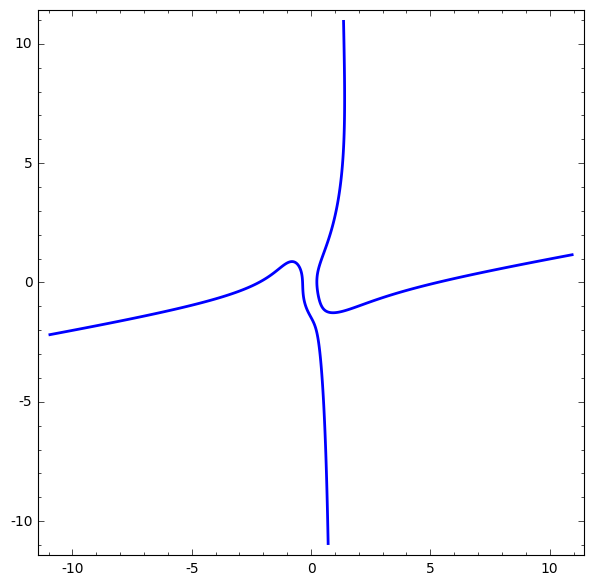

In [12]:
R.<x0,x1,x2> = QQ[]

degree = 4

F = general_curve(degree)
print F

g = plot_curve(F)
g.show()

### Inflectional and double tangents
We compute inflectional points and lines using the hessian determinant.

Number of complex flexes:  24
Number of real flexes:  6


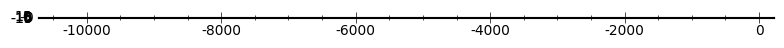

In [13]:
R.<x0,x1,x2> = QQ[]
flex_points_ideal = F + hessian_determinant_curve(F)

print "Number of complex flexes: ", flex_points_ideal.hilbert_polynomial()

# real flex points:
real_flex_points = (flex_points_ideal.subs(x0=1).change_ring(QQ[x1, x2])).variety(RR)
print "Number of real flexes: ", len(real_flex_points)

# compute and show real flex lines
lines=tangents_at_points(F,real_flex_points)

g = plot_curve(F)
g += plot_lines(lines)
g += plot_points(real_flex_points)
g.show()

In [9]:
R2.<u0,u1,u2> = QQ[]
R3.<x0, x1, x2, u0, u1, u2, t> = QQ[]

# two points on u0x0+u1x1+u2x2=0
P = vector([-u1, u0, 0])
Q = vector([0, -u2, u1])

F1 = F.change_ring(R3)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), x2=((P + t * Q)[2]))).gens()[0]

c=poly.polynomial(t).coefficients()

#sub_dict = dict(zip(nodal.ring().gens(),c))

disc = load("discriminants/disc%d_2+2" %(degree))
sub_dict = dict(zip((disc.ring()).gens(),c))


double_lines = disc.subs(sub_dict)
#double_lines = nodal.subs(sub_dict)
double_lines = double_lines.change_ring(R2)

R2.<u0,u1,u2> = QQ[]
double_lines = double_lines.saturation(ideal(u1))[0]

print "Number of complex double lines: ", double_lines.hilbert_polynomial()

real_double_lines = (double_lines.subs(u0=1).change_ring(QQ[u1, u2])).variety(RR)
print "Number of real double lines: ", len(real_double_lines)

if True:
    lines = []
    for l in real_double_lines:
        lines.append([1,l['u1'],l['u2']])

    R.<x1,x2> = QQ[]
    g = plot_curve(F)
    for l in lines:
        line_equation = ideal(l[0] +l[1] *x1 +l[2] *x2).change_ring(RR[x1, x2])
        g += line_equation.plot(color='red')
    g.show()

IOError: [Errno 2] No such file or directory: 'discriminants/disc3_2+2.sobj'

### Dual curve
We can compute the *dual curve* using a similar procedure.

Degree of dual:  12
Ideal (770891*u0^12 - 345275376*u0^11*u1 + 36529482464*u0^10*u1^2 + 474361544050*u0^9*u1^3 + 2164658984968*u0^8*u1^4 + 4350974540564*u0^7*u1^5 + 3261524653509*u0^6*u1^6 + 72832804216*u0^5*u1^7 + 102989063540*u0^4*u1^8 + 26525859442*u0^3*u1^9 + 486607332*u0^2*u1^10 + 374871836*u0*u1^11 + 50740931*u1^12 + 816972*u0^11*u2 - 372483286*u0^10*u1*u2 + 43725529878*u0^9*u1^2*u2 - 288755220628*u0^8*u1^3*u2 - 571314505674*u0^7*u1^4*u2 - 1558470932750*u0^6*u1^5*u2 - 694669316660*u0^5*u1^6*u2 - 37048213082*u0^4*u1^7*u2 - 6543124730*u0^3*u1^8*u2 - 4877751996*u0^2*u1^9*u2 - 14858156*u0*u1^10*u2 - 56672388*u1^11*u2 + 1961030*u0^10*u2^2 + 8534876532*u0^9*u1*u2^2 - 2416187228809*u0^8*u1^2*u2^2 + 7013458940856*u0^7*u1^3*u2^2 - 1688271251231*u0^6*u1^4*u2^2 - 82011167696*u0^5*u1^5*u2^2 - 281347147126*u0^4*u1^6*u2^2 - 42087117946*u0^3*u1^7*u2^2 - 12713128080*u0^2*u1^8*u2^2 + 1601187836*u0*u1^9*u2^2 - 59603998*u1^10*u2^2 + 105713452136*u0^9*u2^3 + 1020078761992*u0^8*u1*u2^3 + 534523888477

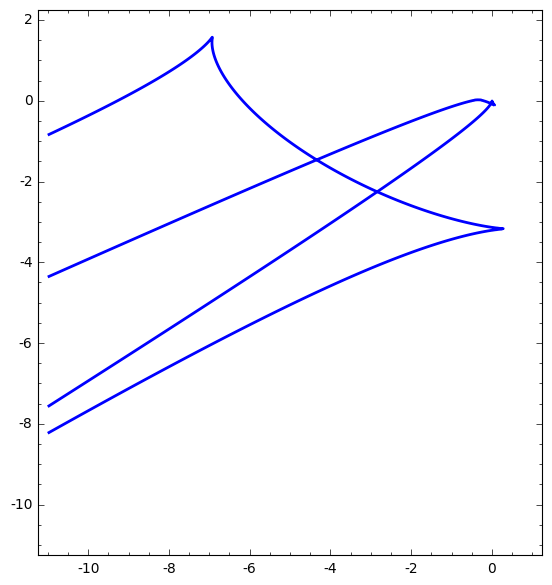

In [5]:
R2.<u0,u1,u2> = QQ[]
R3.<x0, x1, x2, u0, u1, u2, t> = QQ[]

# two points on u0x0+u1x1+u2x2=0
P = vector([-u1, u0, 0])
Q = vector([0, -u2, u1])

F1 = F.change_ring(R3)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), x2=((P + t * Q)[2]))).gens()[0]
dual_curve_p = poly.discriminant(t)
dual_curve = ideal(dual_curve_p) #.change_ring(R2)

dual_curve = dual_curve.saturation(ideal(u1))[0]


print "Degree of dual: ", dual_curve.gens()[0].degree()
print dual_curve
g = plot_curve(dual_curve)
g.show()

### Summary

In [6]:
print "The curve defined by \n", F.gens()[0]
print "Degree: ", degree
print "Degree of dual: ", dual_curve.gens()[0].degree()
print "Inflection points (complex/real): ", flex_points_ideal.hilbert_polynomial(), len(real_flex_points)
print "Bitangents (complex/real): ", double_lines.hilbert_polynomial(), len(real_double_lines)

The curve defined by 
x0^4 - 2*x0^3*x1 - x0^2*x1^2 - 230*x0*x1^3 - x1^4 + 2*x0^3*x2 + 10*x0^2*x1*x2 + x0*x1^2*x2 - 4*x0^2*x2^2 - x0*x1*x2^2 - 39*x0*x2^3 + 13*x1*x2^3 - x2^4
Degree:  4
Degree of dual:  12
Inflection points (complex/real):  24 6
Bitangents (complex/real):  28 4
